# Freight Rate Prediction

The goal is to train a regression model on the historical load data and predict the posted rate for the validation loads. The training data covers January to October 2025, while the final validation data covers November and December 2025.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from catboost import CatBoostRegressor

ROOT = Path.cwd()
DATA = ROOT / "data"

train = pd.read_csv(DATA / "train_test.csv")
validation = pd.read_csv(DATA / "validation.csv")
december = pd.read_csv(DATA / "december_chart_inputs.csv")

train["date"] = pd.to_datetime(train["date"])
validation["date"] = pd.to_datetime(validation["date"])
december["date"] = pd.to_datetime(december["date"])

print("train:", train.shape)
print("validation:", validation.shape)
print("december:", december.shape)

train: (48000, 14)
validation: (12000, 13)
december: (31, 7)


In [2]:
train.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


## Quick data check

In [3]:
print(train.dtypes)
print()
print("Missing values:")
print(train.isna().sum())
print()
print("Negative weights:", (train["weight"] < 0).sum())
print("Unique pickup cities:", train["pickup"].nunique())
print("Unique delivery cities:", train["delivery"].nunique())
print("Unique routes:", (train["pickup"] + "__" + train["delivery"]).nunique())

load_id                 object
pickup                  object
delivery                object
pickup_lat             float64
pickup_lon             float64
delivery_lat           float64
delivery_lon           float64
distance               float64
equipment               object
weight                 float64
date            datetime64[ns]
market_index           float64
quote_signal           float64
posted_rate            float64
dtype: object

Missing values:
load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64

Negative weights: 292
Unique pickup cities: 64
Unique delivery cities: 64
Unique routes: 4014


There are missing values in `weight` and `market_index`. There are also negative weight values. Since a negative shipment weight is not meaningful, the model input uses the absolute value of weight. Missing numeric values are left as missing because CatBoost can handle them directly.

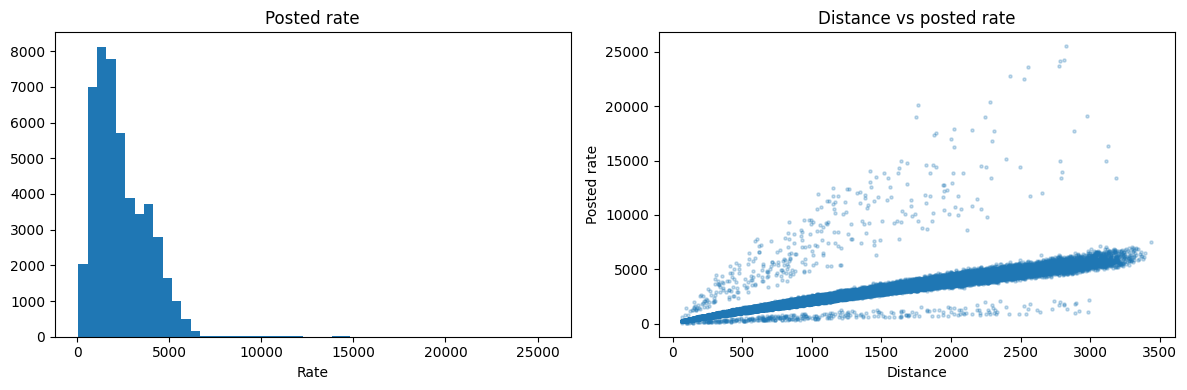

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(train["posted_rate"], bins=50)
axes[0].set_title("Posted rate")
axes[0].set_xlabel("Rate")

axes[1].scatter(train["distance"], train["posted_rate"], s=5, alpha=0.25)
axes[1].set_title("Distance vs posted rate")
axes[1].set_xlabel("Distance")
axes[1].set_ylabel("Posted rate")

plt.tight_layout()
plt.show()

In [5]:
train[["distance", "weight", "market_index", "quote_signal", "posted_rate"]].corr()["posted_rate"].sort_values(ascending=False)

posted_rate     1.000000
distance        0.908519
weight          0.034840
market_index    0.034165
quote_signal   -0.039858
Name: posted_rate, dtype: float64

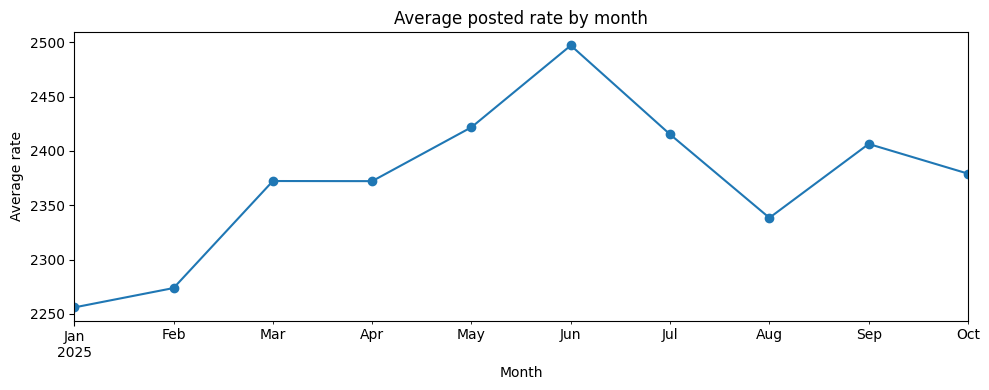

In [6]:
monthly = train.groupby(train["date"].dt.to_period("M"))["posted_rate"].mean()
monthly.plot(figsize=(10, 4), marker="o")
plt.title("Average posted rate by month")
plt.ylabel("Average rate")
plt.xlabel("Month")
plt.tight_layout()
plt.show()

## Feature preparation

In [7]:
city_coords = pd.concat([
    train[["pickup", "pickup_lat", "pickup_lon"]].rename(columns={"pickup": "city", "pickup_lat": "lat", "pickup_lon": "lon"}),
    train[["delivery", "delivery_lat", "delivery_lon"]].rename(columns={"delivery": "city", "delivery_lat": "lat", "delivery_lon": "lon"})
]).groupby("city")[["lat", "lon"]].mean()

def make_features(df):
    x = df.copy()
    x["route"] = x["pickup"].astype(str) + "__" + x["delivery"].astype(str)
    x["month"] = x["date"].dt.month
    x["dayofweek"] = x["date"].dt.dayofweek
    x["dayofyear"] = x["date"].dt.dayofyear
    x["weekofyear"] = x["date"].dt.isocalendar().week.astype(int)
    x["days_since_start"] = (x["date"] - pd.Timestamp("2025-01-01")).dt.days
    x["weight"] = x["weight"].abs()
    x["distance_log"] = np.log1p(x["distance"])
    x["weight_log"] = np.log1p(x["weight"])
    x["distance_per_1000lb"] = x["distance"] / (x["weight"] / 1000).replace(0, np.nan)

    if "pickup_lat" not in x.columns:
        x["pickup_lat"] = x["pickup"].map(city_coords["lat"])
        x["pickup_lon"] = x["pickup"].map(city_coords["lon"])
        x["delivery_lat"] = x["delivery"].map(city_coords["lat"])
        x["delivery_lon"] = x["delivery"].map(city_coords["lon"])

    x["coordinate_gap"] = np.sqrt(
        (x["pickup_lat"] - x["delivery_lat"]) ** 2 +
        (x["pickup_lon"] - x["delivery_lon"]) ** 2
    )
    return x.drop(columns=["load_id", "posted_rate"], errors="ignore")

X = make_features(train)
y = train["posted_rate"]

cat_features = ["pickup", "delivery", "equipment", "route"]
X[cat_features] = X[cat_features].astype(str)

print(X.shape)
print(X.columns.tolist())

(48000, 22)
['pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'route', 'month', 'dayofweek', 'dayofyear', 'weekofyear', 'days_since_start', 'distance_log', 'weight_log', 'distance_per_1000lb', 'coordinate_gap']


## Time-based validation

In [8]:
split_date = pd.Timestamp("2025-10-01")
train_mask = train["date"] < split_date
valid_mask = train["date"] >= split_date

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]
X_valid = X.loc[valid_mask]
y_valid = y.loc[valid_mask]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Validation period:", train.loc[valid_mask, "date"].min().date(), "to", train.loc[valid_mask, "date"].max().date())

Training rows: 43147
Validation rows: 4853
Validation period: 2025-10-01 to 2025-10-31


The split keeps October as a future validation period. This is closer to the real task than randomly mixing future rows into the training set.

## Model

In [9]:
baseline_pred = np.repeat(y_train.mean(), len(y_valid))
baseline_mae = mean_absolute_error(y_valid, baseline_pred)
print(f"Mean-rate baseline MAE: {baseline_mae:,.2f}")

Mean-rate baseline MAE: 1,179.80


In [10]:
model = CatBoostRegressor(
    iterations=1500,
    depth=8,
    learning_rate=0.05,
    loss_function="MAE",
    eval_metric="MAE",
    l2_leaf_reg=5,
    random_seed=42,
    verbose=False,
    thread_count=4
)

model.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=100,
    verbose=False
)

valid_pred = model.predict(X_valid)
mae = mean_absolute_error(y_valid, valid_pred)
rmse = mean_squared_error(y_valid, valid_pred) ** 0.5

print("Best iteration:", model.get_best_iteration())
print(f"Validation MAE: {mae:,.2f}")
print(f"Validation RMSE: {rmse:,.2f}")

Best iteration: 186
Validation MAE: 109.12
Validation RMSE: 647.03


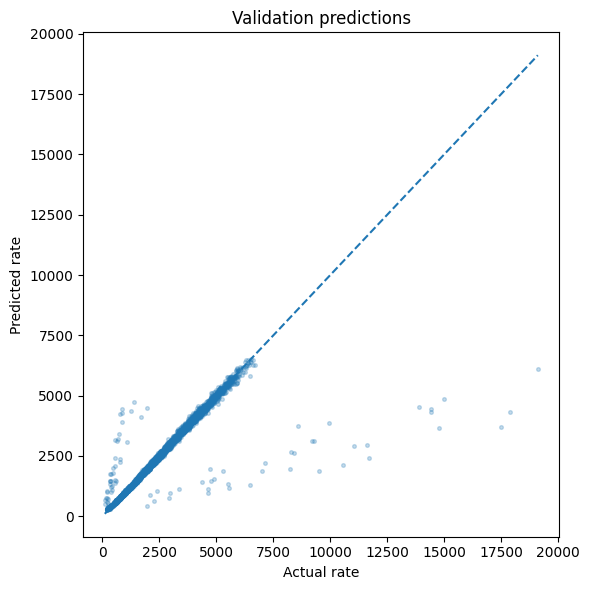

In [11]:
plt.figure(figsize=(6, 6))
plt.scatter(y_valid, valid_pred, s=7, alpha=0.25)
low = min(y_valid.min(), valid_pred.min())
high = max(y_valid.max(), valid_pred.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual rate")
plt.ylabel("Predicted rate")
plt.title("Validation predictions")
plt.tight_layout()
plt.show()

In [12]:
feature_importance = pd.Series(model.get_feature_importance(), index=X.columns)
feature_importance.sort_values(ascending=False).head(12)

distance_log           41.162331
distance               34.439291
coordinate_gap         11.047250
equipment               3.984203
quote_signal            1.898504
delivery_lat            0.965241
distance_per_1000lb     0.722644
delivery_lon            0.713518
market_index            0.661215
pickup_lat              0.641768
delivery                0.624208
pickup_lon              0.619154
dtype: float64

## Train the final model

In [13]:
best_iterations = model.get_best_iteration() + 1
if best_iterations < 50:
    best_iterations = 200

final_model = CatBoostRegressor(
    iterations=best_iterations,
    depth=8,
    learning_rate=0.05,
    loss_function="MAE",
    l2_leaf_reg=5,
    random_seed=42,
    verbose=False,
    thread_count=4
)

final_model.fit(X, y, cat_features=cat_features, verbose=False)
print("Final iterations:", best_iterations)

Final iterations: 187


In [14]:
X_validation = make_features(validation)
X_validation[cat_features] = X_validation[cat_features].astype(str)
validation_pred = final_model.predict(X_validation)
validation_pred = np.maximum(validation_pred, 0.01)

submission = pd.DataFrame({
    "load_id": validation["load_id"],
    "predicted_rate": validation_pred
})

submission.to_csv(ROOT / "validation_predictions.csv", index=False)
print(submission.head())
print("Rows:", len(submission))

     load_id  predicted_rate
0  TE-000001      878.490422
1  TE-000002     4938.038127
2  TE-000003     5179.300657
3  TE-000004     4024.814625
4  TE-000005     1823.057300
Rows: 12000


## December predictions

In [15]:
X_december = make_features(december)
X_december = X_december.reindex(columns=X.columns)
X_december[cat_features] = X_december[cat_features].astype(str)
december["predicted_rate"] = np.maximum(final_model.predict(X_december), 0.01)

december = december[["pickup", "delivery", "distance", "equipment", "weight", "date", "predicted_rate"]]
december.to_csv(DATA / "december_chart_inputs.csv", index=False)

december[["date", "predicted_rate"]]

,date,predicted_rate
0,2025-12-01,818.573053
1,2025-12-02,818.952070
2,2025-12-03,818.952070
3,2025-12-04,818.952070
4,2025-12-05,818.952070
5,2025-12-06,818.333370
6,2025-12-07,817.880224
7,2025-12-08,818.573053
8,2025-12-09,818.952070
9,2025-12-10,818.952070


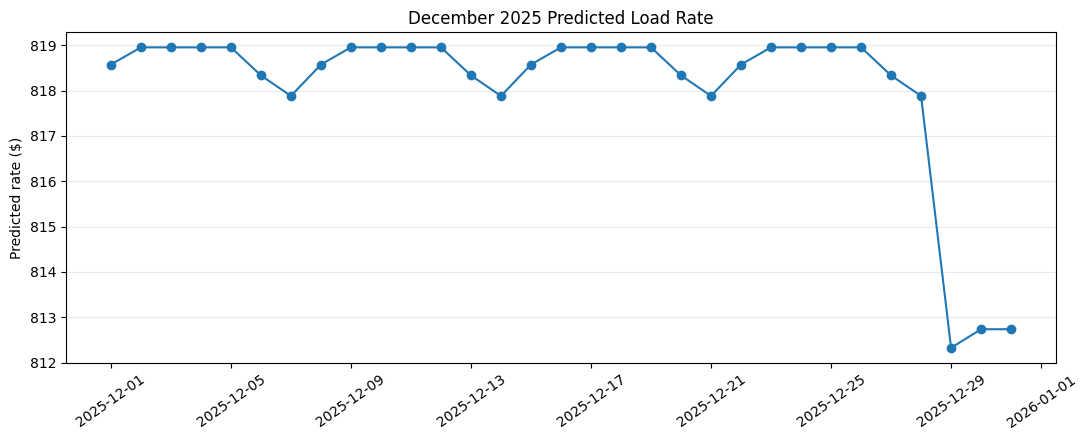

In [16]:
plt.figure(figsize=(11, 4.5))
plt.plot(december["date"], december["predicted_rate"], marker="o")
plt.title("December 2025 Predicted Load Rate")
plt.ylabel("Predicted rate ($)")
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Run the provided scorer

In [17]:
import subprocess
import sys

result = subprocess.run(
    [
        sys.executable,
        str(ROOT / "score.py"),
        "--predictions", str(ROOT / "validation_predictions.csv"),
        "--december-predictions", str(DATA / "december_chart_inputs.csv")
    ],
    capture_output=True,
    text=True
)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.



## Files produced

- `validation_predictions.csv` contains the 12,000 final predictions.
- `scorer_results/candidate_december.png` is the chart required for the assessment report.

The scorer checks the prediction format and the 31 December rows. The final competition metric is calculated by Spotter after submission.